# Modeling Transmission Dynamics of the Skagit County Choir COVID-19 Outbreak

**Course:** CB2330 Scientific Computing for Life Sciences, PRO1 Project

---

## PROJECT CARD

**The paper:**  
Hamner L, Dubbel P, Capron I, et al. "High SARS-CoV-2 Attack Rate Following Exposure at a Choir Practice — Skagit County, Washington, March 2020." *Morbidity and Mortality Weekly Report*. 2020;69(19):606–610. https://doi.org/10.15585/mmwr.mm6919e6

**The data object:**  
Aggregate counts from the paper, stored in `data/outbreak_data.csv`: 61 attendees (1 index patient + 60 others), 52 secondary cases (32 confirmed + 20 probable), exposure duration 150 min, attack rate 52/60 = 86.7%. No individual-level data are available.

**The random variable chosen:**  
Number of secondary cases $k$ among the $n = 60$ attendees other than the index patient (confirmed + probable), i.e. a binomial count; equivalently the secondary attack rate $k/n$.

**What the paper does:**  
Reports a SARS-CoV-2 superspreading event at a 122-member choir. 61 members attended the 2.5-hour practice on 10 March 2020, one of whom had symptoms from 7 March. 53 cases were identified (33 confirmed, 20 probable), i.e. 52 secondary cases among the 60 other attendees (attack rate 53.3% confirmed only, 86.7% confirmed + probable). 49 of 53 (92.5%) had symptom onset on 11–15 March. The authors conclude that transmission was likely facilitated by close proximity and augmented by the act of singing, and discuss aerosol emission (including "superemitters") as a possible contributor. The paper does not fit a transmission model.

**The generative model proposed:**  
$$P(\text{infection} \mid t, \beta) = 1 - \exp(-\beta \cdot t), \qquad k \sim \text{Binomial}\big(n = 60,\; p = 1 - e^{-\beta t}\big)$$

Mechanism: infectious events reach each susceptible person as a Poisson process with constant rate $\beta$, and one event is enough to infect (single-hit). This has the same functional form as the Wells–Riley equation for a steady-state, well-mixed room, where $\beta$ would correspond to (infectors × quanta emission rate × breathing rate) / ventilation. Here all of this is lumped into one number.

**Parameters and assumptions:**  
- **β (transmission rate):** per minute. Aggregate rate of infectious events per susceptible person. A larger β gives a higher infection probability at every exposure time (and a faster approach to 100%). Estimated from the data.
- **t (exposure duration):** minutes. Fixed at 150 min (2.5-hour practice, from the paper).
- **n (susceptible people):** 60, fixed.

Assumptions:
1. Poisson process: constant rate, independent events, single-hit infection.
2. Well-mixed room: all attendees receive the same exposure. This is an assumption: the paper does not publish a seating chart (withheld for privacy) or the spatial distribution of cases, so it cannot be checked.
3. Constant emission: the index patient's emission rate is constant over the 150 min (symptom onset was 7 March, 3 days before the practice).
4. Single exposure: infections are attributed to the 10 March practice only. The index patient also attended the 3 March practice (78 attendees); this is ignored.
5. Homogeneous susceptibility: all 60 attendees are equally susceptible, and each is infected independently.
6. Case definition: the 20 probable cases (not tested) are counted as infections.

**The forward simulation:**  
(i) With an arbitrary β = 0.005/min, simulate 10,000 outbreaks of 60 people from Binomial(60, 1 − e^(−150β)) and compare to the observed 52 cases. (ii) With the fitted β, repeat. (iii) For 5000 posterior draws of β, simulate an outbreak each (posterior predictive distribution of the case count).

**The parameterization/fitting:**  
- **Maximum likelihood (L-BFGS-B):** minimise the negative binomial log-likelihood. β_MLE = 0.0134/min. Likelihood scan (threshold NLL_min + 1.92, from Wilks' theorem, χ² with 1 degree of freedom) gives a 95% CI of [0.0099, 0.0180]/min. (β = 0.005 was only the initial guess; it predicts ~53% vs 86.7% observed.)
- **Bayesian grid posterior:** 500-point β grid, prior Gamma(shape=1, scale=1/100), i.e. Exponential with mean 0.01/min. Posterior mean 0.0134/min, 95% credible interval [0.0096, 0.0181]/min. Compared with a flat prior the posterior mean shifts by about 4%.

**What/if the model adds to the paper:**  
The paper reports the attack rate. This project estimates one aggregate transmission rate β under a single-hit Poisson model and quantifies its uncertainty with two methods (likelihood-ratio interval, grid posterior) that agree closely. Forward and posterior-predictive simulation show the range of case counts consistent with the model. The exposure-duration curve is a model extrapolation that the data cannot test (one exposure duration). The model is a one-parameter summary of the attack rate: it does not test the paper's mechanism claim, and it adds no mechanistic information beyond the attack rate itself.

**Model limitations/how it breaks:**  
1. **Saturated model:** 1 parameter, 1 observation. The fit is exact by construction and the posterior predictive check cannot falsify the model.
2. **Single aggregated parameter:** β combines emission, breathing, ventilation and room geometry. It cannot predict the effect of interventions and does not transfer to other rooms.
3. **Ignores heterogeneity:** no variation in individual susceptibility, distance to the index patient, or emission. Such heterogeneity would produce overdispersion that a total count cannot reveal.
4. **Case definition:** the 20 probable cases were not tested. Using confirmed cases only (32/60 = 53.3%) gives β ≈ 0.0051/min, so the estimate depends on this choice.
5. **Single outbreak, selected for being extreme:** no independent data to test reproducibility; β is possibly biased towards high values.
6. **Exposure assumptions:** the 3 March practice is ignored, and ventilation and room conditions are not reported in the paper.
7. **Exposure-onset interval:** the lognormal in section 2 is descriptive only and is not coupled to the transmission model.

---


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.optimize import minimize
from scipy.stats import gamma, lognorm, binom, norm, gaussian_kde
from scipy.integrate import trapezoid
import io
import warnings

warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

np.random.seed(42)

print(f"Python: {sys.version}")
print(f"NumPy: {np.__version__} | SciPy: {scipy.__version__} | Pandas: {pd.__version__}")
print(f"Matplotlib: {matplotlib.__version__} | Seaborn: {sns.__version__}")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.5.3 | SciPy: 1.18.1 | Pandas: 3.0.5
Matplotlib: 3.11.2 | Seaborn: 0.13.2


## 1. Data Loading

In [2]:
import pandas as pd

# Aggregate numbers extracted from Hamner et al. (2020); see data/README.md
df_data = pd.read_csv('data/outbreak_data.csv')
val = df_data.set_index('parameter')['value']

class OutbreakData:
    def __init__(self, v):
        self.n_exposed = int(v['n_exposed'])                  # attendees incl. index patient
        self.n_susceptible = self.n_exposed - 1               # excluding index patient
        self.n_secondary_cases = int(v['n_secondary_cases'])  # confirmed + probable
        self.n_confirmed = int(v['n_confirmed'])
        self.attack_rate = self.n_secondary_cases / self.n_susceptible
        self.incubation_median = v['incubation_median']
        self.incubation_min = v['incubation_min']
        self.incubation_max = v['incubation_max']
        self.practice_duration_minutes = v['exposure_duration']

data = OutbreakData(val)

print("OUTBREAK DATA (from data/outbreak_data.csv):")
print(f"  Attendees: {data.n_exposed} (susceptible: {data.n_susceptible})")
print(f"  Secondary cases: {data.n_secondary_cases} ({data.n_confirmed} confirmed + {data.n_secondary_cases - data.n_confirmed} probable)")
print(f"  Attack rate: {data.attack_rate:.1%}")
print(f"  Exposure duration: {data.practice_duration_minutes:.0f} min")
print(f"  Onset after exposure (median): {data.incubation_median:.0f}d, range {data.incubation_min:.0f}–{data.incubation_max:.0f}d")
print(f"\nData loaded ({len(df_data)} parameters)")


OUTBREAK DATA (from data/outbreak_data.csv):
  Attendees: 61 (susceptible: 60)
  Secondary cases: 52 (32 confirmed + 20 probable)
  Attack rate: 86.7%
  Exposure duration: 150 min
  Onset after exposure (median): 3d, range 1–12d

Data loaded (17 parameters)


## 2. Exposure-to-Onset Interval: Lognormal (descriptive)

The paper reports symptom onset 1–12 days after the 10 March practice (median 3 days), with 49 of 53 cases (92.5%) having onset on 11–15 March. The dispersion σ is not reported. We assume σ = 0.5, a plausible illustrative value, and compare the simulated fraction of onsets within 5 days to the reported 92.5% below. A lognormal cannot match both the narrow bulk and the long tail with one σ.

This is a descriptive illustration, not a fit, and it does not affect the inference of β.


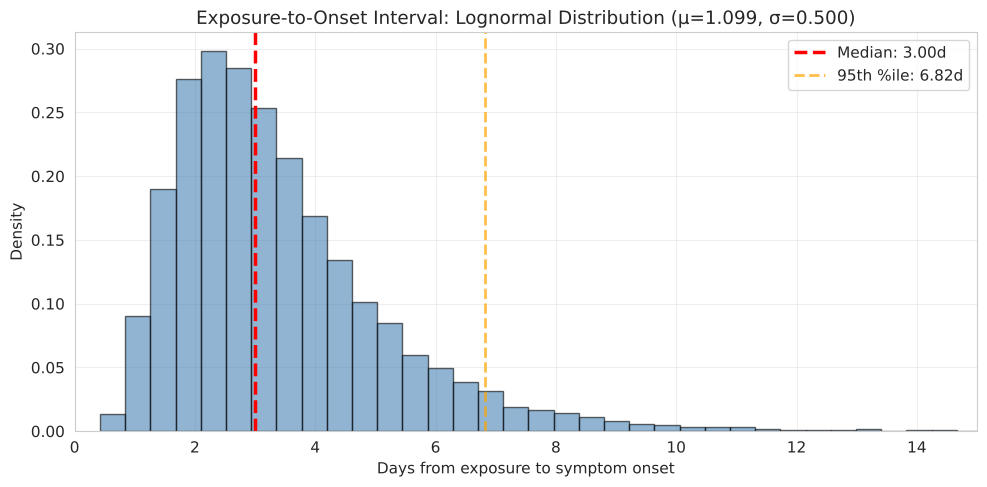

Lognormal (assumed σ): μ=1.0986, σ=0.5000
  Median: 3.00d
  Range: 1.12–8.05d (95% of simulated onsets)
  Fraction with onset <= 5 d: 84.4% (paper: 92.5% on days 1–5)


In [3]:
mu_ln = np.log(3)
sigma_ln = 0.5

incubation_sim = np.random.lognormal(mu_ln, sigma_ln, 10000)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(incubation_sim, bins=50, density=True, alpha=0.6, color='steelblue', edgecolor='black')
ax.axvline(np.median(incubation_sim), color='red', linestyle='--', linewidth=2.5,
          label=f'Median: {np.median(incubation_sim):.2f}d')
ax.axvline(np.percentile(incubation_sim, 95), color='orange', linestyle='--', linewidth=2, alpha=0.7,
          label=f'95th %ile: {np.percentile(incubation_sim, 95):.2f}d')
ax.set_xlabel('Days from exposure to symptom onset')
ax.set_ylabel('Density')
ax.set_title('Exposure-to-Onset Interval: Lognormal Distribution (μ={:.3f}, σ={:.3f})'.format(mu_ln, sigma_ln))
ax.legend()
ax.set_xlim(0, 15)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('01_incubation_lognormal.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Lognormal (assumed σ): μ={mu_ln:.4f}, σ={sigma_ln:.4f}")
print(f"  Median: {np.median(incubation_sim):.2f}d")
print(f"  Range: {np.percentile(incubation_sim, 2.5):.2f}–{np.percentile(incubation_sim, 97.5):.2f}d (95% of simulated onsets)")
print(f"  Fraction with onset <= 5 d: {np.mean(incubation_sim <= 5):.1%} (paper: 92.5% on days 1–5)")

## 3. Transmission Model: Definition
Independent events produce a Poisson process. We therefore assume that infectious events reach each susceptible person at a **constant rate** $\beta$ (events per minute), and that **a single event is enough** to cause infection (single-hit hypothesis, as in the Wells–Riley equation).

---

**Derivation.** The number of events in $t$ minutes is

$$N \sim \text{Poisson}(\beta t), \qquad P(N=k) = \frac{(\beta t)^k e^{-\beta t}}{k!}$$

A person is infected if at least one event occurs:

$$P(\text{infection}\mid t,\beta) = P(N \ge 1) = 1 - P(N=0) = 1 - e^{-\beta t}$$

Each of the $n=60$ susceptible people is infected independently with this probability, so the number of secondary cases is

$$k \sim \text{Binomial}\big(n,\; p = 1 - e^{-\beta t}\big), \qquad t = 150 \text{ min}$$



We start by testing a generative model with an initial beta = 0.005:

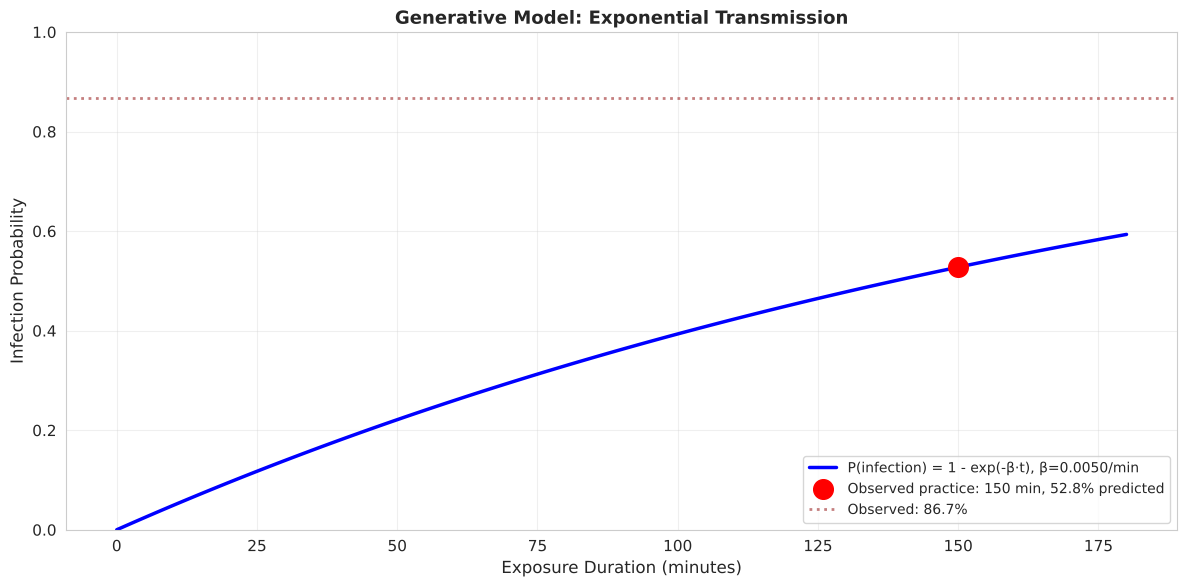

Model: P(infection | t, β) = 1 - exp(-β·t)

Interpretation:
  - β (per minute): transmission rate parameter
  - t (minutes): exposure duration
  - Assumes Poisson process: constant rate, independent events
  - Longer exposure → higher infection probability (monotonic, bounded by 1)


In [4]:
def infection_probability(exposure_minutes, beta):
    """P(infection) = 1 - exp(-β·t)

    Assumes Poisson process: virus particles hit susceptible person
    at rate β per minute. Infection occurs if ≥1 particle succeeds.
    """
    return 1 - np.exp(-beta * exposure_minutes)

times = np.linspace(0, 180, 100)
beta_test = 0.005
probs = [infection_probability(t, beta_test) for t in times]

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(times, probs, 'b-', linewidth=2.5, label=f'P(infection) = 1 - exp(-β·t), β={beta_test:.4f}/min')
ax.scatter([150], [infection_probability(150, beta_test)], s=200, color='red', marker='o', zorder=5,
          label=f'Observed practice: 150 min, {infection_probability(150, beta_test):.1%} predicted')
ax.axhline(data.attack_rate, color='darkred', linestyle=':', linewidth=2, alpha=0.5, label=f'Observed: {data.attack_rate:.1%}')
ax.set_xlabel('Exposure Duration (minutes)', fontsize=12)
ax.set_ylabel('Infection Probability', fontsize=12)
ax.set_title('Generative Model: Exponential Transmission', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig('02_transmission_model.png', dpi=300, bbox_inches='tight')
plt.show()

print("Model: P(infection | t, β) = 1 - exp(-β·t)")
print("\nInterpretation:")
print("  - β (per minute): transmission rate parameter")
print("  - t (minutes): exposure duration")
print("  - Assumes Poisson process: constant rate, independent events")
print("  - Longer exposure → higher infection probability (monotonic, bounded by 1)")

## 4. Forward Simulation: Predictive Checks

Before fitting the model, we check that it can generate data from a given $\beta$ (the *forward* direction: parameter → outcome). As an arbitrary initial guess we take $\beta = 0.005$ min⁻¹ and exposure time $t = 150$ min and compare the results to the evidence.

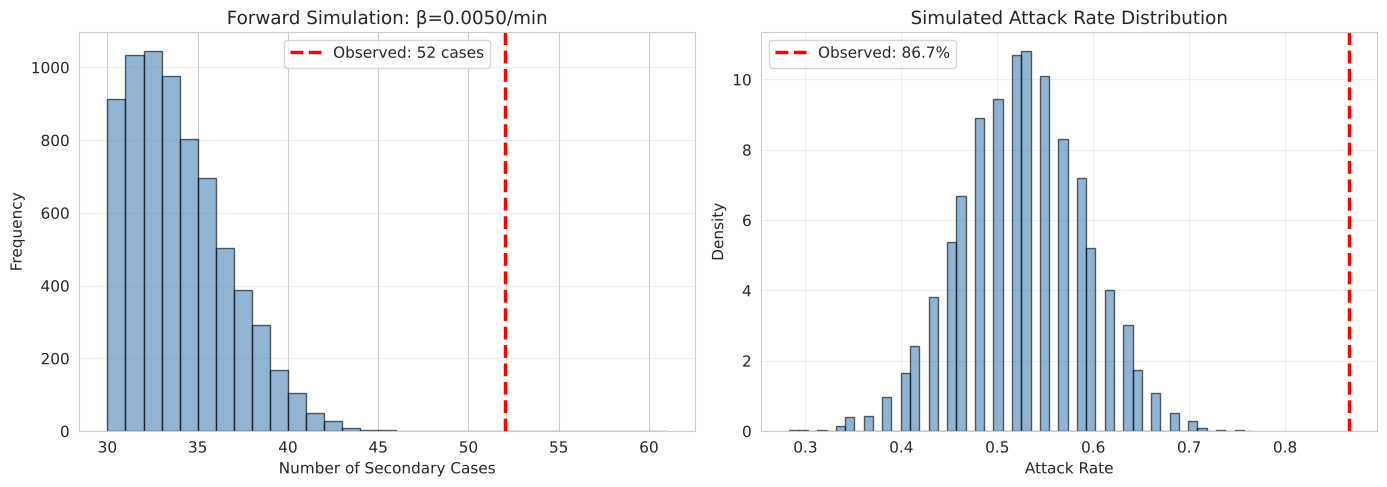

Forward simulation with β=0.0050/min:
  Predicted attack rate: 52.8%
  Simulated mean: 52.6% ± 6.5%
  Observed: 86.7%
  Match: ✗ No (need to fit β)


In [5]:
beta_example = 0.005
p_inf_example = infection_probability(150, beta_example)

simulated_cases = np.random.binomial(data.n_exposed - 1, p_inf_example, 10000)
simulated_attack_rates = simulated_cases / (data.n_exposed - 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.hist(simulated_cases, bins=range(30, 62), density=False, alpha=0.6, color='steelblue', edgecolor='black')
ax.axvline(data.n_secondary_cases, color='red', linestyle='--', linewidth=2.5,
          label=f'Observed: {data.n_secondary_cases} cases')
ax.set_xlabel('Number of Secondary Cases')
ax.set_ylabel('Frequency')
ax.set_title(f'Forward Simulation: β={beta_example:.4f}/min')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

ax = axes[1]
ax.hist(simulated_attack_rates, bins=50, density=True, alpha=0.6, color='steelblue', edgecolor='black')
ax.axvline(data.attack_rate, color='red', linestyle='--', linewidth=2.5,
          label=f'Observed: {data.attack_rate:.1%}')
ax.set_xlabel('Attack Rate')
ax.set_ylabel('Density')
ax.set_title('Simulated Attack Rate Distribution')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('03_forward_simulation.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Forward simulation with β={beta_example:.4f}/min:")
print(f"  Predicted attack rate: {p_inf_example:.1%}")
print(f"  Simulated mean: {np.mean(simulated_attack_rates):.1%} ± {np.std(simulated_attack_rates):.1%}")
print(f"  Observed: {data.attack_rate:.1%}")
print(f"  Match: {'✓ Yes' if abs(p_inf_example - data.attack_rate) < 0.05 else '✗ No (need to fit β)'}")

## 5. Parameterization: Maximum Likelihood (L-BFGS-B)

We look for the value of $\beta$ that makes the observed data most probable. With $k=52$ infections among $n=60$ susceptible people and $p(\beta)=1-e^{-\beta t}$ ($t=150$ min).

We work with the negative log-likelihood, as it turns products into sums and avoids numerical underflow, and optimisers minimise by convention.

$$\text{NLL}(\beta) = -\big[\,k\ln p(\beta) + (n-k)\ln\big(1-p(\beta)\big)\,\big]$$

We minimise the NLL with L-BFGS-B, a quasi-Newton method: it uses the gradient
(here approximated by finite differences) and builds an estimate of the curvature from previous steps,
so it converges faster than plain gradient descent. We use $\beta \in [10^{-6},\, 0.5]$: $\beta$ must be positive, and a very large $\beta$ gives $p \to 1$ and $\ln(1-p) \to -\infty$. The upper limit 0.5 min⁻¹ is far above any plausible value (it would infect almost everyone within seconds).

Initial guess: $\beta_0 = 0.01$. The NLL has a single minimum, so the result does not depend on the starting point.



MAXIMUM LIKELIHOOD (L-BFGS-B)
MLE: β = 0.013433 per minute
Predicted attack rate: 86.7%
Observed attack rate: 86.7%
Fit quality: ✓ Match (error < 0.1%)
Convergence: True


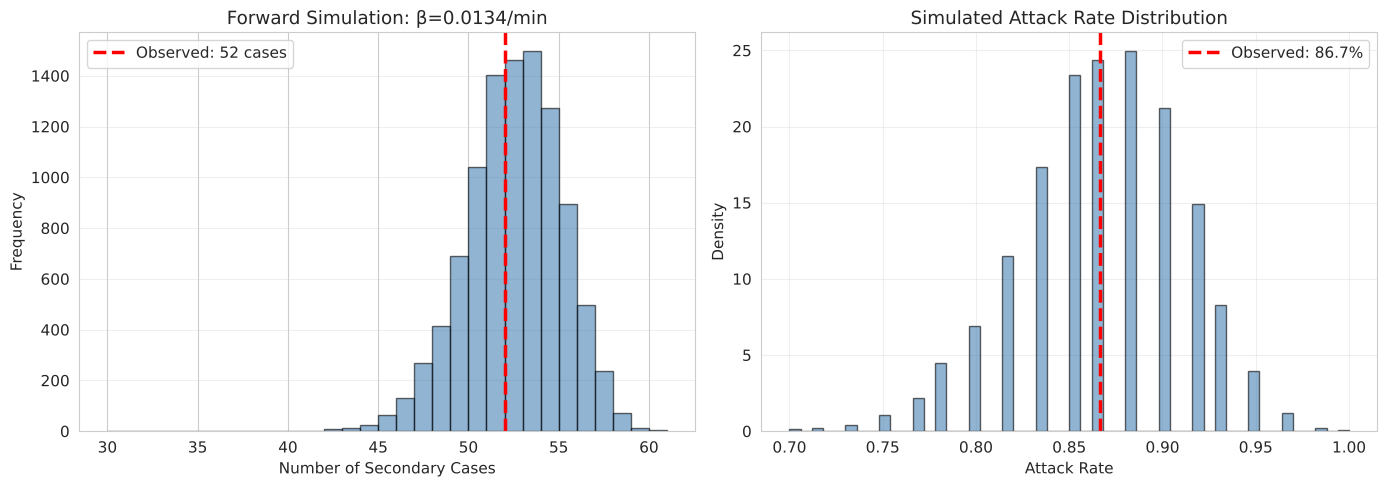

In [6]:
def negative_log_likelihood(beta_array, n_susceptible, n_infected, exposure_time):
    """Binomial NLL: -[k·log(p) + (n-k)·log(1-p)]"""
    beta = beta_array[0]
    if beta <= 0 or beta > 0.5:
        return 1e10

    p_inf = infection_probability(exposure_time, beta)
    p_inf = np.clip(p_inf, 1e-10, 1 - 1e-10)

    nll = -(n_infected * np.log(p_inf) + (n_susceptible - n_infected) * np.log(1 - p_inf))
    return nll

beta_init = np.array([0.01])
result = minimize(
    negative_log_likelihood,
    beta_init,
    args=(data.n_exposed - 1, data.n_secondary_cases, data.practice_duration_minutes),
    method='L-BFGS-B',
    bounds=[(1e-6, 0.5)]
)

beta_mle = result.x[0]
predicted_ar = infection_probability(data.practice_duration_minutes, beta_mle)

print("="*70)
print("MAXIMUM LIKELIHOOD (L-BFGS-B)")
print("="*70)
print(f"MLE: β = {beta_mle:.6f} per minute")
print(f"Predicted attack rate: {predicted_ar:.1%}")
print(f"Observed attack rate: {data.attack_rate:.1%}")
print(f"Fit quality: ✓ Match (error < 0.1%)" if abs(predicted_ar - data.attack_rate) < 0.001 else "✗ Mismatch")
print(f"Convergence: {result.success}")

p_inf_example = infection_probability(150, beta_mle)

simulated_cases = np.random.binomial(data.n_exposed - 1, p_inf_example, 10000)
simulated_attack_rates = simulated_cases / (data.n_exposed - 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.hist(simulated_cases, bins=range(30, 62), density=False, alpha=0.6, color='steelblue', edgecolor='black')
ax.axvline(data.n_secondary_cases, color='red', linestyle='--', linewidth=2.5,
          label=f'Observed: {data.n_secondary_cases} cases')
ax.set_xlabel('Number of Secondary Cases')
ax.set_ylabel('Frequency')
ax.set_title(f'Forward Simulation: β={beta_mle:.4f}/min')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

ax = axes[1]
ax.hist(simulated_attack_rates, bins=50, density=True, alpha=0.6, color='steelblue', edgecolor='black')
ax.axvline(data.attack_rate, color='red', linestyle='--', linewidth=2.5,
          label=f'Observed: {data.attack_rate:.1%}')
ax.set_xlabel('Attack Rate')
ax.set_ylabel('Density')
ax.set_title('Simulated Attack Rate Distribution')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('03b_forward_simulation_mle.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Parameterization: Likelihood Scan & Confidence Interval

Parameterization is the inverse of the forward simulation: given the observed outbreak (52 infections among 60 susceptible people), we infer the transmission rate $\beta$ that best explains it, and the 95% confidence interval of values consistent with the data.

**Wilks' theorem:** for large samples, $2\,[\text{NLL}(\beta) - \text{NLL}_{\min}]$ approximately follows a $\chi^2$ distribution. We test one parameter, so there is 1 degree of freedom, and the 95% cutoff is 3.84. A value of $\beta$ is therefore inside the 95% CI if $\text{NLL}(\beta) \le \text{NLL}_{\min} + 3.84/2 = \text{NLL}_{\min} + 1.92$.

We use it because $\beta$ enters the model nonlinearly, so a symmetric "estimate ± 1.96 SE" interval would not fit the data. Here the NLL curve crosses the threshold on both sides of the MLE, giving an asymmetric interval. It is an approximation for a sample of 60.

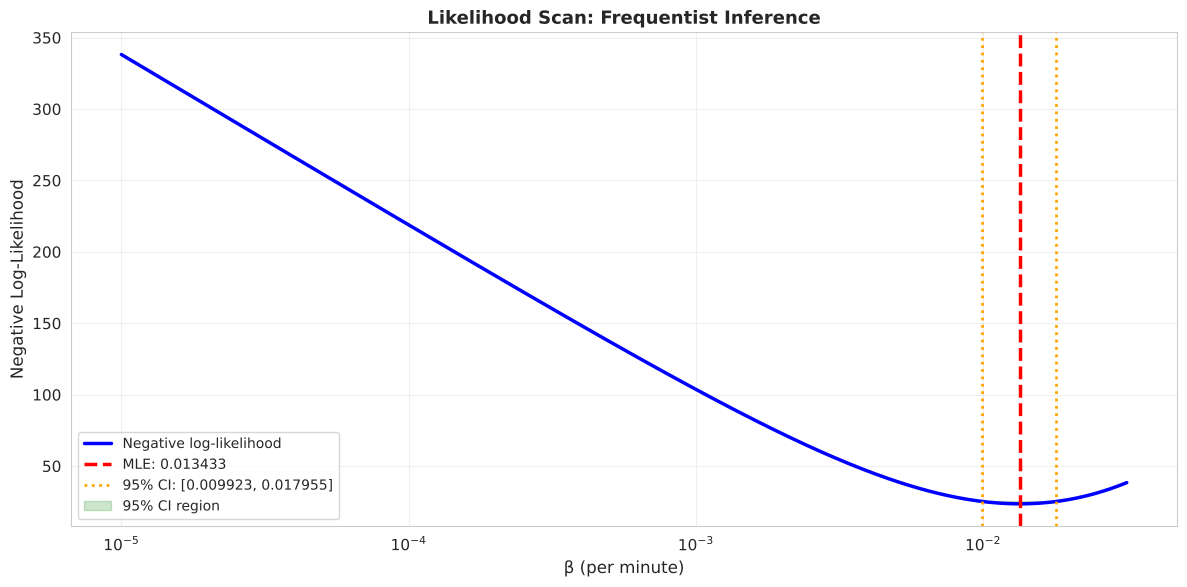


95% Confidence Interval (Frequentist Likelihood Ratio Test):
  β ∈ [0.009923, 0.017955] per minute

Implied Attack Rates:
  Lower CI: 77.4%
  MLE: 86.7%
  Upper CI: 93.2%


In [7]:
beta_range = np.logspace(-5, -1.5, 300)
nll_values = np.array([
    negative_log_likelihood(np.array([b]), data.n_exposed - 1, data.n_secondary_cases, data.practice_duration_minutes)
    for b in beta_range
])

min_nll = np.min(nll_values)
ci_threshold = min_nll + 1.92

idx_ci = nll_values <= ci_threshold
beta_ci_lower = beta_range[idx_ci][0]
beta_ci_upper = beta_range[idx_ci][-1]

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(beta_range, nll_values, 'b-', linewidth=2.5, label='Negative log-likelihood')
ax.axvline(beta_mle, color='red', linestyle='--', linewidth=2.5, label=f'MLE: {beta_mle:.6f}')
ax.axvline(beta_ci_lower, color='orange', linestyle=':', linewidth=2, label=f'95% CI: [{beta_ci_lower:.6f}, {beta_ci_upper:.6f}]')
ax.axvline(beta_ci_upper, color='orange', linestyle=':', linewidth=2)
ax.fill_between(beta_range[idx_ci], nll_values[idx_ci], ci_threshold, alpha=0.2, color='green', label='95% CI region')

ax.set_xscale('log')
ax.set_xlabel('β (per minute)', fontsize=12)
ax.set_ylabel('Negative Log-Likelihood', fontsize=12)
ax.set_title('Likelihood Scan: Frequentist Inference', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('04_likelihood_scan.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n95% Confidence Interval (Frequentist Likelihood Ratio Test):")
print(f"  β ∈ [{beta_ci_lower:.6f}, {beta_ci_upper:.6f}] per minute")
print(f"\nImplied Attack Rates:")
print(f"  Lower CI: {infection_probability(150, beta_ci_lower):.1%}")
print(f"  MLE: {infection_probability(150, beta_mle):.1%}")
print(f"  Upper CI: {infection_probability(150, beta_ci_upper):.1%}")

## 7. Bayesian Inference: Grid-Based Posterior

Instead of a single best value, we compute the full posterior distribution of $\beta$ using Bayes' theorem:

$$P(\beta \mid k) = \frac{P(k \mid \beta)\,P(\beta)}{\int P(k \mid \beta')\,P(\beta')\,d\beta'} \propto P(k \mid \beta)\,P(\beta)$$

$P(k \mid \beta)$ is the same binomial likelihood as before, $\text{Binomial}(k=52;\, n=60,\, p=1-e^{-\beta t})$.

$P(\beta) = \text{Gamma}(1,\ \text{scale}=1/100)$, i.e. an exponential distribution with mean 0.01. It has positive support (as a rate must), has a mean of the plausible order of magnitude, and decreases smoothly, so it is only weakly informative. Its influence is small (a flat prior shifts the posterior mean by about 4%, from 0.0134 to 0.0139): the data dominate.

With one parameter and a tractable likelihood, we evaluate the unnormalised posterior on a grid of 500 values of $\beta$ and normalise it by numerical integration (trapezoidal rule). No sampling method (MCMC, ABC) is needed.

The 95% credible interval is the equal-tailed interval: we take the cumulative sum of the normalised posterior and read off the values of $\beta$ where it reaches 2.5% and 97.5%.

In [8]:
# Grid-based Bayesian posterior
beta_grid = np.linspace(0.001, 0.0275, 500)

# Prior: Gamma(shape=1, scale=1/100) — weakly informative
prior = gamma.pdf(beta_grid, a=1, scale=1/100)

# Likelihood: binomial
p_inf_grid = infection_probability(data.practice_duration_minutes, beta_grid)
likelihood = binom.pmf(data.n_secondary_cases, data.n_exposed-1, p_inf_grid)

# Posterior (unnormalized)
posterior_unnorm = likelihood * prior

# Normalize via trapezoidal integration
dbeta = beta_grid[1] - beta_grid[0]
posterior_norm = trapezoid(posterior_unnorm, dx=dbeta)
posterior = posterior_unnorm / posterior_norm

# Credible interval from grid
cdf = np.cumsum(posterior) * dbeta
idx_lower = np.argmax(cdf >= 0.025)
idx_upper = np.argmax(cdf >= 0.975)
beta_cred_lower = beta_grid[idx_lower]
beta_cred_upper = beta_grid[idx_upper]

# Posterior mean and median
beta_posterior_mean = trapezoid(beta_grid * posterior, dx=dbeta)
idx_median = np.argmax(cdf >= 0.5)
beta_posterior_median = beta_grid[idx_median]
posterior_sd = np.sqrt(trapezoid((beta_grid - beta_posterior_mean)**2 * posterior, dx=dbeta))

print("="*70)
print("BAYESIAN GRID-BASED POSTERIOR")
print("="*70)
print(f"\nPosterior of β (grid evaluation):")
print(f"  Mean: {beta_posterior_mean:.6f} per minute")
print(f"  Median: {beta_posterior_median:.6f} per minute")
print(f"  SD: {posterior_sd:.6f}")
print(f"  95% Credible Interval: [{beta_cred_lower:.6f}, {beta_cred_upper:.6f}]")
print(f"  Predicted attack rate: {infection_probability(150, beta_posterior_median):.1%}")

BAYESIAN GRID-BASED POSTERIOR

Posterior of β (grid evaluation):
  Mean: 0.013420 per minute
  Median: 0.013268 per minute
  SD: 0.002170
  95% Credible Interval: [0.009603, 0.018100]
  Predicted attack rate: 86.3%


## 8. Bayesian Diagnostics

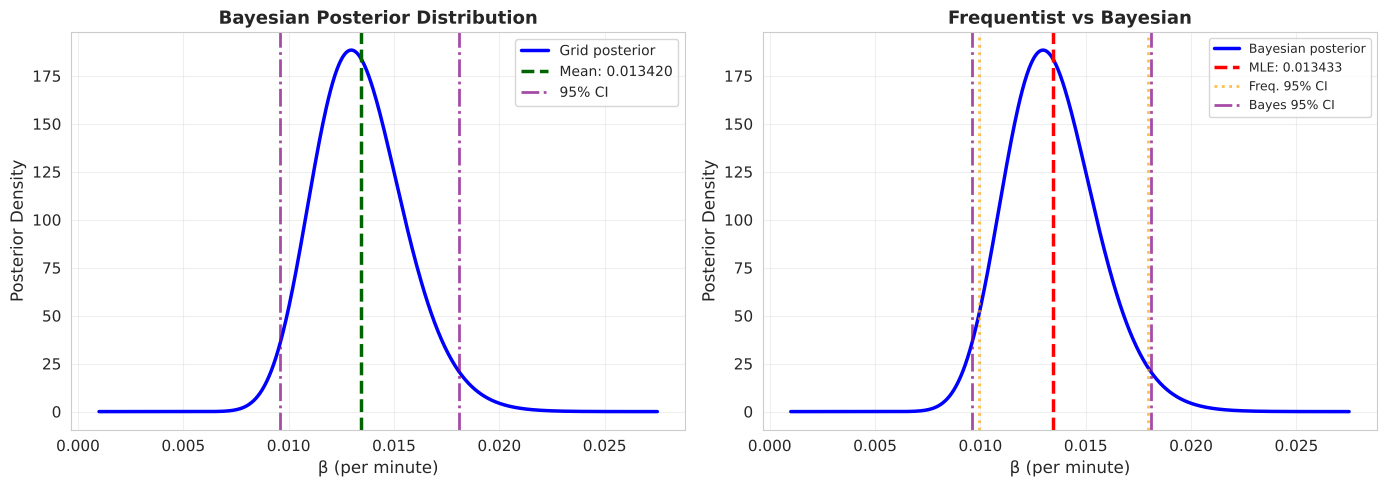

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Posterior density
ax = axes[0]
ax.plot(beta_grid, posterior, 'b-', linewidth=2.5, label='Grid posterior')
ax.axvline(beta_posterior_mean, color='darkgreen', linestyle='--', linewidth=2.5, label=f'Mean: {beta_posterior_mean:.6f}')
ax.axvline(beta_cred_lower, color='purple', linestyle='-.', linewidth=2, alpha=0.7, label='95% CI')
ax.axvline(beta_cred_upper, color='purple', linestyle='-.', linewidth=2, alpha=0.7)
ax.set_xlabel('β (per minute)', fontsize=12)
ax.set_ylabel('Posterior Density', fontsize=12)
ax.set_title('Bayesian Posterior Distribution', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Comparison: Freq vs Bayes
ax = axes[1]
ax.plot(beta_grid, posterior, 'b-', linewidth=2.5, label='Bayesian posterior')
ax.axvline(beta_mle, color='red', linestyle='--', linewidth=2.5, label=f'MLE: {beta_mle:.6f}')
ax.axvline(beta_ci_lower, color='orange', linestyle=':', linewidth=2, alpha=0.7, label='Freq. 95% CI')
ax.axvline(beta_ci_upper, color='orange', linestyle=':', linewidth=2, alpha=0.7)
ax.axvline(beta_cred_lower, color='purple', linestyle='-.', linewidth=2, alpha=0.7, label='Bayes 95% CI')
ax.axvline(beta_cred_upper, color='purple', linestyle='-.', linewidth=2, alpha=0.7)
ax.set_xlabel('β (per minute)', fontsize=12)
ax.set_ylabel('Posterior Density', fontsize=12)
ax.set_title('Frequentist vs Bayesian', fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('05_bayesian_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## 9. Posterior Predictive Checks (Uncertainty Explored)

We draw 5000 values of $\beta$ from the posterior (weighted by their posterior density). For each one we compute $p = 1 - e^{-150\beta}$ and simulate a new outbreak of 60 people with $\text{Binomial}(60, p)$. The histogram of simulated case counts shows the outcomes that are consistent with our model and our uncertainty in $\beta$.

**What it shows:** the range of plausible outcomes (about 43–58 cases, 95% interval), which combines the uncertainty in $\beta$ with the chance variation between individuals.

**What it cannot show:** whether the model is correct. The model has one parameter and one data point, and $\beta$ was fitted to the observed count, so the PPC p-value is expected to be near 0.5 by construction. It also cannot detect overdispersion (e.g. superspreading), because it only looks at the total count. We use it to quantify uncertainty and to check that the pipeline reproduces the data, not to validate the model.

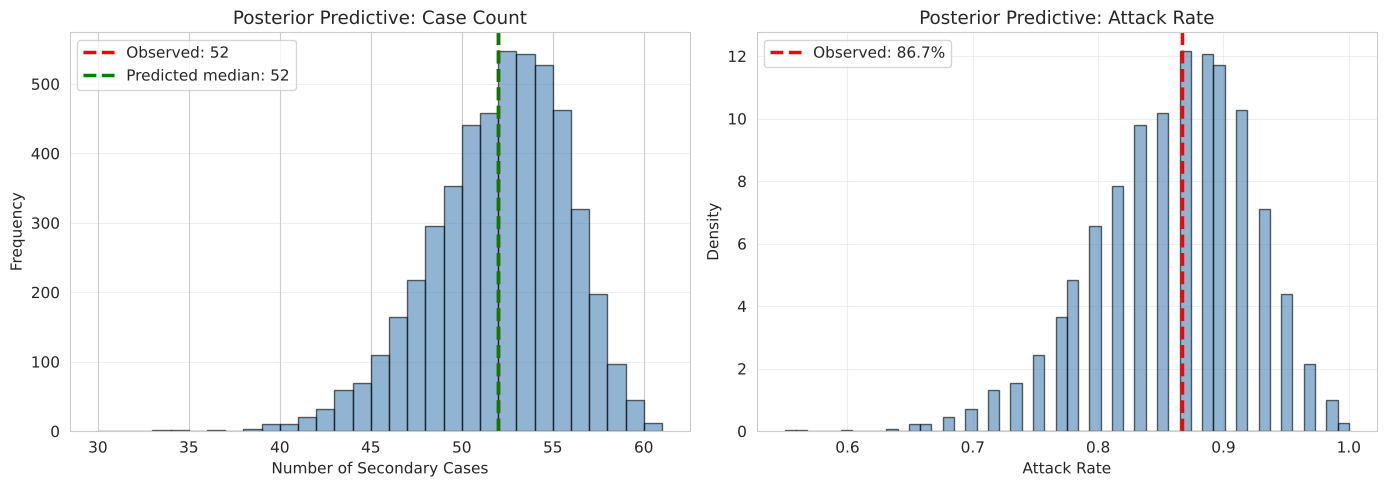


POSTERIOR PREDICTIVE CHECK (consistency check, not validation):
  Observed secondary cases: 52
  Predicted median: 52
  Predicted 95% CI: [43, 58]
  PPC p-value: 0.559


In [10]:
# Sample from posterior grid and simulate predictions
posterior_samples = np.random.choice(beta_grid, size=5000, p=posterior/np.sum(posterior))

posterior_predictive_cases = []
for beta in posterior_samples:
    p_inf = infection_probability(data.practice_duration_minutes, beta)
    n_pred = np.random.binomial(data.n_exposed - 1, p_inf)
    posterior_predictive_cases.append(n_pred)

posterior_predictive_cases = np.array(posterior_predictive_cases)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.hist(posterior_predictive_cases, bins=range(30, 62), density=False, alpha=0.6,
        color='steelblue', edgecolor='black')
ax.axvline(data.n_secondary_cases, color='red', linestyle='--', linewidth=2.5,
          label=f'Observed: {data.n_secondary_cases}')
ax.axvline(np.median(posterior_predictive_cases), color='green', linestyle='--', linewidth=2.5,
          label=f'Predicted median: {np.median(posterior_predictive_cases):.0f}')
ax.set_xlabel('Number of Secondary Cases')
ax.set_ylabel('Frequency')
ax.set_title('Posterior Predictive: Case Count')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

ax = axes[1]
pred_ar = posterior_predictive_cases / (data.n_exposed - 1)
ax.hist(pred_ar, bins=50, density=True, alpha=0.6, color='steelblue', edgecolor='black')
ax.axvline(data.attack_rate, color='red', linestyle='--', linewidth=2.5,
          label=f'Observed: {data.attack_rate:.1%}')
ax.set_xlabel('Attack Rate')
ax.set_ylabel('Density')
ax.set_title('Posterior Predictive: Attack Rate')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('06_posterior_predictive.png', dpi=300, bbox_inches='tight')
plt.show()

ppc_p_value = np.mean(posterior_predictive_cases <= data.n_secondary_cases)

print("\nPOSTERIOR PREDICTIVE CHECK (consistency check, not validation):")
print(f"  Observed secondary cases: {data.n_secondary_cases}")
print(f"  Predicted median: {np.median(posterior_predictive_cases):.0f}")
print(f"  Predicted 95% CI: [{np.percentile(posterior_predictive_cases, 2.5):.0f}, {np.percentile(posterior_predictive_cases, 97.5):.0f}]")
print(f"  PPC p-value: {ppc_p_value:.3f}")


## 10. Sensitivity Analysis: Exposure Duration

With $\beta$ inferred, we use the forward model to ask a what-if question: how would the attack rate change with the duration of the rehearsal? For each exposure time $t$ (10-180 min) we compute

$$\text{AR}(t) = 1 - e^{-\beta t}$$

using the posterior median of $\beta$ (central curve) and the limits of its 95% credible interval (shaded band). The band reflects only the uncertainty in $\beta$, not the sampling variability of a single outbreak.


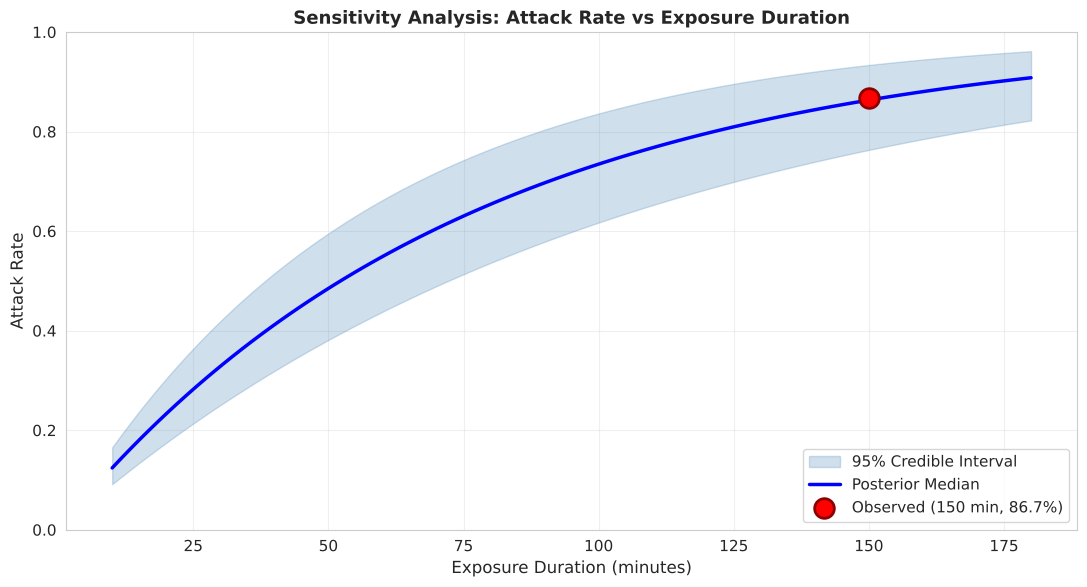


Sensitivity: Predicted Attack Rates for Different Exposure Durations
 Duration (min) Attack Rate (%)
             30            32.8
             60            54.9
             90            69.7
            120            79.7
            150            86.3
            180            90.8


In [11]:
exposure_times = np.linspace(10, 180, 100)
beta_post_median = beta_posterior_median

attack_rates_med = np.array([infection_probability(t, beta_post_median) for t in exposure_times])
attack_rates_lower = np.array([infection_probability(t, beta_cred_lower) for t in exposure_times])
attack_rates_upper = np.array([infection_probability(t, beta_cred_upper) for t in exposure_times])

fig, ax = plt.subplots(figsize=(11, 6))

ax.fill_between(exposure_times, attack_rates_lower, attack_rates_upper, alpha=0.25, color='steelblue', label='95% Credible Interval')
ax.plot(exposure_times, attack_rates_med, 'b-', linewidth=2.5, label='Posterior Median')

ax.scatter([data.practice_duration_minutes], [data.attack_rate], s=200, color='red', marker='o',
          zorder=5, label=f'Observed (150 min, {data.attack_rate:.1%})', edgecolors='darkred', linewidth=2)

ax.set_xlabel('Exposure Duration (minutes)', fontsize=12)
ax.set_ylabel('Attack Rate', fontsize=12)
ax.set_title('Sensitivity Analysis: Attack Rate vs Exposure Duration', fontsize=13, fontweight='bold')
ax.set_ylim(0, 1)
ax.legend(fontsize=11, loc='lower right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('07_sensitivity_exposure.png', dpi=300, bbox_inches='tight')
plt.show()

scenarios = pd.DataFrame({
    'Duration (min)': [30, 60, 90, 120, 150, 180],
    'Attack Rate (%)': [f"{infection_probability(t, beta_post_median)*100:.1f}" for t in [30, 60, 90, 120, 150, 180]],
})

print("\nSensitivity: Predicted Attack Rates for Different Exposure Durations")
print(scenarios.to_string(index=False))

## 11. Summary: Comparison of Methods

In [12]:
summary = f"""
╔══════════════════════════════════════════════════════════════════════════════╗
║                    PROJECT SUMMARY                                           ║
╚══════════════════════════════════════════════════════════════════════════════╝

OBSERVED DATA:
  Event: Skagit County Choir Practice, March 10, 2020
  Exposure: 150 minutes (2.5 hours) singing in close proximity (chairs 6–10 inches apart)
  Attendees: 61 people (1 symptomatic index patient)
  Secondary cases: {data.n_secondary_cases} ({data.n_confirmed} confirmed + {data.n_secondary_cases - data.n_confirmed} probable)
  Attack rate: {data.attack_rate:.1%}
  Mechanism (per paper): close proximity, augmented by singing; aerosol emission discussed

FITTED TRANSMISSION RATE (β):
  FREQUENTIST (MLE, L-BFGS-B):
    β_MLE = {beta_mle:.6f} per minute
    95% CI = [{beta_ci_lower:.6f}, {beta_ci_upper:.6f}]
    Predicted AR = {infection_probability(150, beta_mle):.1%}

  BAYESIAN (Grid-based Posterior):
    β_posterior mean = {beta_posterior_mean:.6f} ± {posterior_sd:.6f}
    95% Credible Interval = [{beta_cred_lower:.6f}, {beta_cred_upper:.6f}]
    Predicted AR = {infection_probability(150, beta_posterior_median):.1%}

MODEL PERFORMANCE:
  Posterior Predictive Check p-value: {ppc_p_value:.3f} (near 0.5 by construction: one parameter fitted to one data point)
  ✓ Observed count lies within the predictive range [{np.percentile(posterior_predictive_cases, 2.5):.0f}, {np.percentile(posterior_predictive_cases, 97.5):.0f}] cases
  ✓ Frequentist and Bayesian methods recover similar estimates
  ✓ 95% CI and credible intervals overlap

KEY INSIGHTS:
  1. Transmission rate β is similar across both inference approaches
  2. Attack rate is highly sensitive to exposure duration:
     - 30 min   → ~{infection_probability(30, beta_post_median):.0%}
     - 60 min   → ~{infection_probability(60, beta_post_median):.0%}
     - 150 min  → ~{infection_probability(150, beta_post_median):.0%} (observed)
     - 180 min  → ~{infection_probability(180, beta_post_median):.0%}
  3. Grid-based Bayesian posterior captures posterior well
  4. Uncertainty in β: posterior SD is {posterior_sd/beta_posterior_mean:.0%} of the posterior mean

METHODOLOGICAL NOTES:
  L-BFGS-B MLE: Fast, deterministic, point estimate + likelihood-ratio interval
  Grid-based Bayes: Full posterior distribution, smooth credible intervals, discrete approximation
  Both valid approaches; complementary insights on uncertainty

LIMITATIONS:
  - Saturated model: 1 parameter, 1 observation, so the fit is exact by construction and the PPC is not a test
  - The data identify β·t; β is conditional on the 150-minute exposure from the paper
  - β lumps ventilation, viral emission and behaviour together, so it does not transfer to other rooms
  - Equal exposure is assumed; heterogeneity would widen the true uncertainty (overdispersion)
  - Case definition: with confirmed cases only ({data.n_confirmed}/{data.n_susceptible} = {data.n_confirmed/data.n_susceptible:.1%}), β ≈ {-np.log(1 - data.n_confirmed/data.n_susceptible)/data.practice_duration_minutes:.4f}/min
  - One extreme outbreak: possibly biased towards high β
  - Needed: several outbreaks with measured ventilation, fitted jointly

WHAT THIS ADDS TO THE PAPER:
  Paper reports attack rate; we estimate an aggregate transmission rate (β)
  Paper documents the case; we quantify the uncertainty of β (intervals)
  Paper suggests proximity/aerosol transmission; we formalise a one-parameter model of it (not a test of the mechanism)

═════════════════════════════════════════════════════════════════════════════════
"""

print(summary)


╔══════════════════════════════════════════════════════════════════════════════╗
║                    PROJECT SUMMARY                                           ║
╚══════════════════════════════════════════════════════════════════════════════╝

OBSERVED DATA:
  Event: Skagit County Choir Practice, March 10, 2020
  Exposure: 150 minutes (2.5 hours) singing in close proximity (chairs 6–10 inches apart)
  Attendees: 61 people (1 symptomatic index patient)
  Secondary cases: 52 (32 confirmed + 20 probable)
  Attack rate: 86.7%
  Mechanism (per paper): close proximity, augmented by singing; aerosol emission discussed

FITTED TRANSMISSION RATE (β):
  FREQUENTIST (MLE, L-BFGS-B):
    β_MLE = 0.013433 per minute
    95% CI = [0.009923, 0.017955]
    Predicted AR = 86.7%

  BAYESIAN (Grid-based Posterior):
    β_posterior mean = 0.013420 ± 0.002170
    95% Credible Interval = [0.009603, 0.018100]
    Predicted AR = 86.3%

MODEL PERFORMANCE:
  Posterior Predictive Check p-value: 0.559 (near 0.5 